https://github.com/sihsieh65-tech/cs82a-portfolio/tree/main/Final_project

Setting up the tools and loading the netflix data. I then ran basic diagnostics to examine my dataset. 

In [1]:
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
df=pd.read_csv("netflix_customer_churn.csv")

In [2]:
df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [3]:
df.tail()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
4995,44f3ba44-b95d-4e50-a786-bac4d06f4a43,19,Female,Basic,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action
4998,7b0ad82d-6571-430e-90f4-906259e0e89c,59,Female,Basic,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi
4999,82aeef39-ddb0-40ad-bae1-5c436e0cf042,57,Male,Basic,1.62,17,Africa,Mobile,8.99,1,Crypto,2,0.09,Action


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 547.0

Since sklearn can only use numerical values for decision trees I am planning to drop most of the categorical features. I did convert gender and region to numbers to see if I could use them successfully in sklearn. 

In [5]:
gender_mapping = {'Male': 1, 'Female': 2, 'Other': 3}
df['gender'] = df['gender'].replace(gender_mapping)
df['gender'] = df['gender'].astype(int)
region_mapping = {'North America':1,'South America':2,'Europe':3,'Asia':4,'Africa':5, 'Oceania':6}
df['region'] = df['region'].replace(region_mapping)
df['region'] = df['region'].astype(int)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   int64  
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   int64  
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(6), str(5)
memory usage: 547.0

I then create the train/test split, then run my data through a decision tree. 

In [7]:
from sklearn.model_selection import train_test_split
X = df.drop(["churned","customer_id",'subscription_type','device','payment_method', 'favorite_genre'], axis=1)
y = df["churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [8]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(max_depth=3)

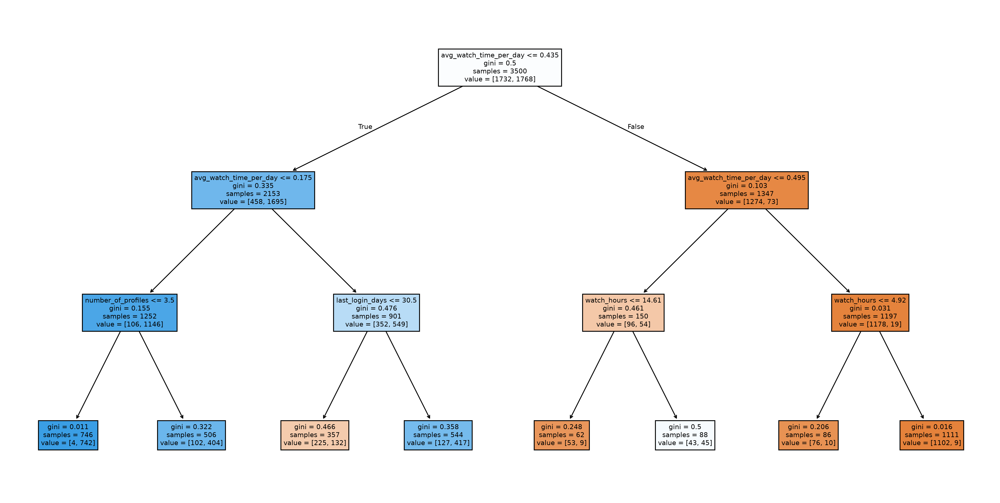

In [9]:
tree.fit(X_train, y_train)
from sklearn.tree import plot_tree
plt.figure(figsize=(20, 10), dpi=300)
plot_tree(tree, feature_names= ['age', 'gender', 'watch_hours','last_login_days','region','montly_fee','number_of_profiles','avg_watch_time_per_day'], filled=True)
plt.show()

In [10]:
print(tree.score(X_train, y_train))
print(tree.score(X_test, y_test))

0.8754285714285714
0.8786666666666667


Trying a different way to show the results that might be a bit more readable than the tree diagram. 

In [11]:
tree_structure = tree.tree_

rows = []
for node_id in range(tree_structure.node_count):
  is_leaf = tree_structure.children_left[node_id] == tree_structure.children_right[node_id]

  rows.append({
      'Node ID': node_id,
      'Left Child': (
          None if is_leaf else tree_structure.children_left[node_id]
      ),
      'Right Child': (
          None if is_leaf else tree_structure.children_right[node_id]
      ),
      'Total Samples': tree_structure.n_node_samples[node_id],
      'Class Distribution': tree_structure.value[node_id][0].tolist(),
      'Gini Impurity': round(tree_structure.impurity[node_id], 4),
      'Is Leaf': is_leaf,
  })

gini_df = pd.DataFrame(rows)
print(gini_df)

    Node ID  Left Child  Right Child  Total Samples  \
0         0         1.0          8.0           3500   
1         1         2.0          5.0           2153   
2         2         3.0          4.0           1252   
3         3         NaN          NaN            746   
4         4         NaN          NaN            506   
5         5         6.0          7.0            901   
6         6         NaN          NaN            357   
7         7         NaN          NaN            544   
8         8         9.0         12.0           1347   
9         9        10.0         11.0            150   
10       10         NaN          NaN             62   
11       11         NaN          NaN             88   
12       12        13.0         14.0           1197   
13       13         NaN          NaN             86   
14       14         NaN          NaN           1111   

                            Class Distribution  Gini Impurity  Is Leaf  
0     [0.4948571428571429, 0.5051428571428571]

While my original scores were good, I want to test if I can achieve an even better score using a higher max depth. I repeated my methods for depths= 4, 5, and 6.

In [12]:
X2 = df.drop(["churned","customer_id",'subscription_type','device','payment_method', 'favorite_genre'], axis=1)
y2 = df["churned"]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.3, random_state=42)
tree2 = DecisionTreeClassifier(max_depth=4)

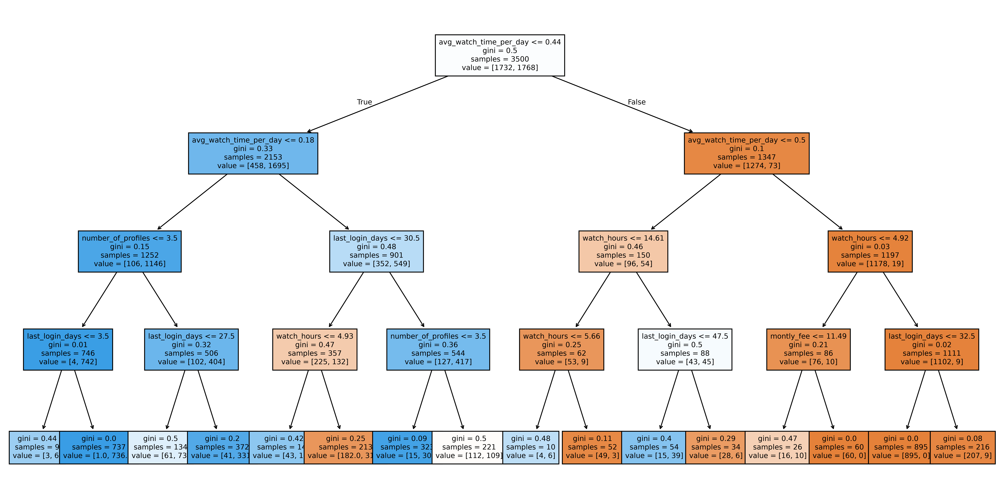

In [13]:
tree2.fit(X2_train, y2_train)
plt.figure(figsize=(20, 10), dpi=600)
plot_tree(
    tree2, 
    feature_names= ['age', 'gender', 'watch_hours','last_login_days','region','montly_fee','number_of_profiles','avg_watch_time_per_day'], 
    filled=True,
    fontsize=8,       
    precision=2       
)
plt.show()

In [14]:
print(tree2.score(X2_train, y2_train))
print(tree2.score(X2_test, y2_test))

0.8997142857142857
0.8893333333333333


In [15]:
tree_structure2 = tree2.tree_

rows2 = []
for node_id in range(tree_structure2.node_count):
  is_leaf2 = tree_structure2.children_left[node_id] == tree_structure2.children_right[node_id]

  rows2.append({
      'Node ID': node_id,
      'Left Child': (
          None if is_leaf2 else tree_structure2.children_left[node_id]
      ),
      'Right Child': (
          None if is_leaf2 else tree_structure2.children_right[node_id]
      ),
      'Total Samples': tree_structure2.n_node_samples[node_id],
      'Class Distribution': tree_structure2.value[node_id][0].tolist(),
      'Gini Impurity': round(tree_structure2.impurity[node_id], 4),
      'Is Leaf': is_leaf2,
  })

gini_df2 = pd.DataFrame(rows2)
print(gini_df2)

    Node ID  Left Child  Right Child  Total Samples  \
0         0         1.0         16.0           3500   
1         1         2.0          9.0           2153   
2         2         3.0          6.0           1252   
3         3         4.0          5.0            746   
4         4         NaN          NaN              9   
5         5         NaN          NaN            737   
6         6         7.0          8.0            506   
7         7         NaN          NaN            134   
8         8         NaN          NaN            372   
9         9        10.0         13.0            901   
10       10        11.0         12.0            357   
11       11         NaN          NaN            144   
12       12         NaN          NaN            213   
13       13        14.0         15.0            544   
14       14         NaN          NaN            323   
15       15         NaN          NaN            221   
16       16        17.0         24.0           1347   
17       1

I also continued to increase the depth to see if I had optimized the model. Based on my results it appears that better accuracy is still achieveable at depths 5 and 6, however the maps become increasingly noisy and difficult to read. I also stopped reporting the Gini Impuritiy tables that I did at depth 3 and 4 as they would become increasingly large and cumbersome to read. 

In [16]:
X3 = df.drop(["churned","customer_id",'subscription_type','device','payment_method', 'favorite_genre'], axis=1)
y3 = df["churned"]
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.3, random_state=42)
tree3 = DecisionTreeClassifier(max_depth=5)
tree3.fit(X3_train, y3_train)
plt.figure(figsize=(36, 20), dpi=600)
plot_tree(tree3, feature_names= ['age', 'gender', 'watch_hours','last_login_days','region','montly_fee','number_of_profiles','avg_watch_time_per_day'], filled=True)
plt.show()

In [17]:
print(tree3.score(X3_train, y3_train))
print(tree3.score(X3_test, y3_test))

0.9314285714285714
0.916


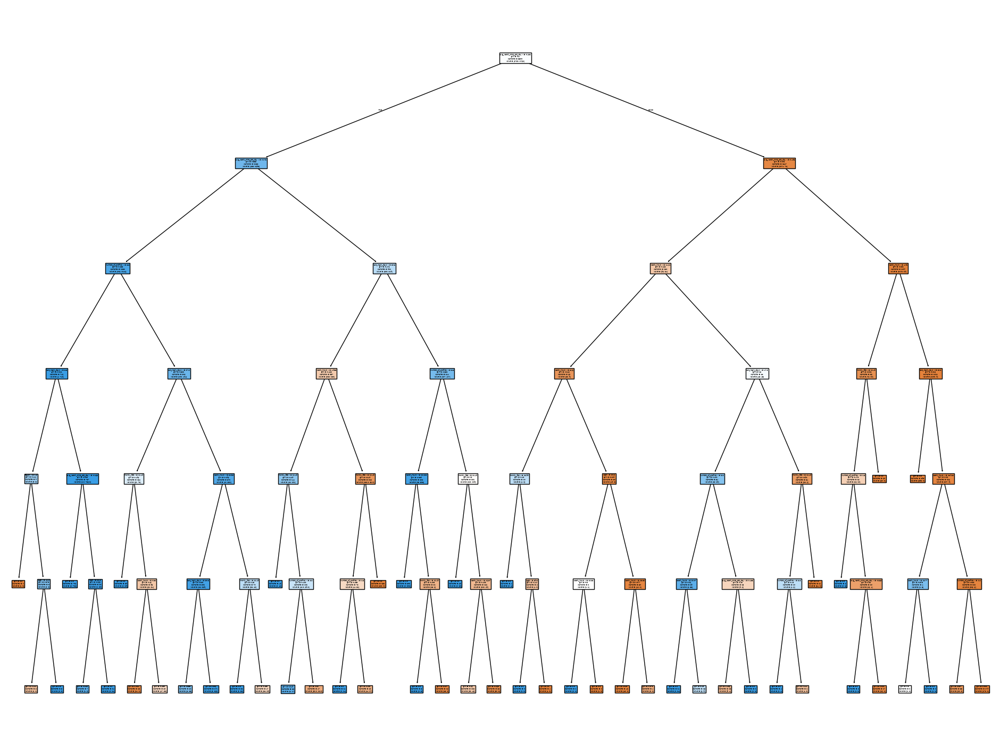

In [18]:
X4 = df.drop(["churned","customer_id",'subscription_type','device','payment_method', 'favorite_genre'], axis=1)
y4 = df["churned"]
X4_train, X4_test, y4_train, y4_test = train_test_split(X4, y4, test_size=0.3, random_state=42)
tree4 = DecisionTreeClassifier(max_depth=6)
tree4.fit(X4_train, y4_train)
plt.figure(figsize=(24, 18))
plot_tree(tree4, feature_names= ['age', 'gender', 'watch_hours','last_login_days','region','montly_fee','number_of_profiles','avg_watch_time_per_day'], filled=True)
plt.show()

In [19]:
print(tree4.score(X4_train, y4_train))
print(tree4.score(X4_test, y4_test))

0.9494285714285714
0.9326666666666666


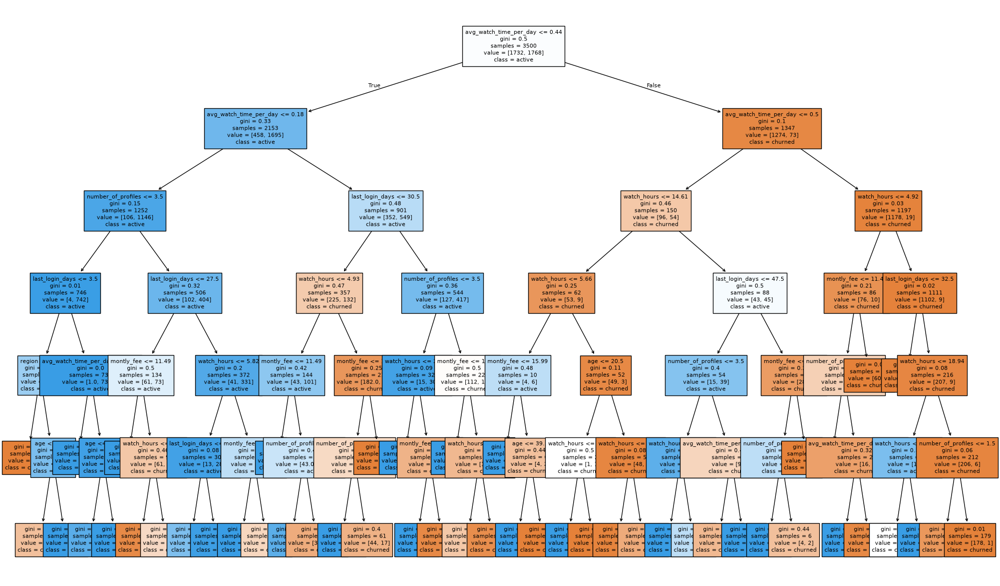

In [20]:
plt.figure(figsize=(25, 15)) 
feature_names= 'age', 'gender', 'watch_hours','last_login_days','region','montly_fee','number_of_profiles','avg_watch_time_per_day'
class_names= 'churned','active'
plot_tree(
    tree4,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    fontsize=8,       
    precision=2       
)

plt.show()

Based on the results it appears the most important features for predicting churn are the average watch time per day, the number of profiles, the days since the last login, and the montly watched hours. These four features comprise the top layers of the decision tree at depth 3 and 4. In fact the only other feature that appears in the top 4 levels is the montly fee and that only appears once in the 15 nodes available.   

If ive correctly identified the features that are the most important I should be able to recreate a similar score (train= 0.90 and test= 0.89) at the same depth (max depth=4) using only the top features mentioned above. Conversely, I can use the removed features and recieve a comparabily lower score.

In [21]:
X_top = df.drop(["churned","customer_id",'subscription_type','device','payment_method', 'favorite_genre','age', 'gender','region','monthly_fee'], axis=1)
y_top = df["churned"]
X_top_train, X_top_test, y_top_train, y_top_test = train_test_split(X_top, y_top, test_size=0.3, random_state=42)
tree_top = DecisionTreeClassifier(max_depth=4)
tree_top.fit(X_top_train, y_top_train)
plt.figure(figsize=(36, 20), dpi=600)
plot_tree(tree_top, feature_names= [ 'watch_hours','last_login_days','number_of_profiles','avg_watch_time_per_day'], filled=True)
plt.show()

In [22]:
print(tree_top.score(X_top_train, y_top_train))
print(tree_top.score(X_top_test, y_top_test))

0.9
0.8893333333333333


In [23]:
treedata = {
    'Study name': ['8_feature_tree', 'top_feature_tree'],
    'Train score': [0.90, 0.90],
    'Test score': [0.89, 0.89]
}
df2 = pd.DataFrame(treedata)
df2

,Study name,Train score,Test score
0,8_feature_tree,0.9,0.89
1,top_feature_tree,0.9,0.89


These scores are very comparable to the ones I recieved when I used the full 8 features. 

In [24]:
X_bottom = df.drop(["churned","customer_id",'subscription_type','device', 'payment_method', 'favorite_genre', 'watch_hours','last_login_days','number_of_profiles','avg_watch_time_per_day'], axis=1)
y_bottom = df["churned"]
X_bottom_train, X_bottom_test, y_bottom_train, y_bottom_test = train_test_split(X_bottom, y_bottom, test_size=0.3, random_state=42)
tree_bottom = DecisionTreeClassifier(max_depth=4)
tree_bottom.fit(X_bottom_train, y_bottom_train)
plt.figure(figsize=(36, 20), dpi=600)
plot_tree(tree_bottom, feature_names= [ 'age', 'gender','region','monthly_fee'], filled=True)
plt.show()

In [25]:
print(tree_bottom.score(X_bottom_train, y_bottom_train))
print(tree_bottom.score(X_bottom_test, y_bottom_test))

0.5805714285714285
0.5733333333333334


In [26]:
treedata2 = {
    'Study name': ['8_feature_tree', 'top_feature_tree','bottom_feature_tree'],
    'Train score': [0.90, 0.90, 0.58],
    'Test score': [0.89, 0.89, 0.57]
}
df3 = pd.DataFrame(treedata2)
df3

,Study name,Train score,Test score
0,8_feature_tree,0.90,0.89
1,top_feature_tree,0.90,0.89
2,bottom_feature_tree,0.58,0.57


These scores are signficantly worse than the scores I got with the full 8 features. 

Ways to improve the study: Ideally, I would test my model against another, comparable dataset to see if the same features arise as the most important. If I consistently observe the same results then we can feel more confident that the most important features have been identified. I would also continue to increase the depth until the score stops improving, though this is unlikely to change the final result. Lastly, I would have loved to do this study with something other than sklearn as it largely limits me to using only numerical columns. I would have preferred being able to use the categorical column as well. 